# Customer Churn Analysis

**The question I wanted to answer:** which telecom customers are leaving, why, and who should the retention team call first?

**Data:** IBM Telco Customer Churn, 7,043 customers and 21 columns (`../data/telco_customer_churn.csv`).

**How I worked:** I cleaned the data, compared churn across customer groups, checked which differences are real, built a model to score every customer, and then turned the scores into a call list and a rough revenue estimate.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import chi2_contingency

BLUE, LIGHT, SAGE, CORAL, SAND, NAVY = "#6F8FAE", "#A9BDD0", "#8FB0A2", "#D9917F", "#E0C492", "#3F566E"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#C9D3DC", "axes.labelcolor": "#44505C",
                     "xtick.color": "#44505C", "ytick.color": "#44505C", "font.size": 11,
                     "axes.titleweight": "semibold", "axes.titlesize": 13})
IMG = Path("../images"); IMG.mkdir(exist_ok=True)
df = pd.read_csv("../data/telco_customer_churn.csv")
df.shape

(7043, 21)

## 1. Data cleaning and checks

In [2]:
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

# TotalCharges is stored as text; 11 rows are blank spaces
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank = df[df["TotalCharges"].isna()]
print("\nBlank TotalCharges rows:", len(blank), "| their tenure values:", blank["tenure"].unique())

Duplicate customer IDs: 0
Missing values per column:
Series([], dtype: int64)

Blank TotalCharges rows: 11 | their tenure values: [0]


All 11 blank `TotalCharges` rows are customers with **tenure 0**. They had just signed up and not been billed yet, so I set them to 0 and kept the rows.

In [3]:
# Two more checks before trusting the data
profile_cols = [c for c in df.columns if c != "customerID"]
print("Rows identical to another row (apart from the ID):", df.duplicated(subset=profile_cols).sum())
print("Tenure range:", df.tenure.min(), "to", df.tenure.max(), "months")
print("Monthly charges range: $%.2f to $%.2f" % (df.MonthlyCharges.min(), df.MonthlyCharges.max()))

Rows identical to another row (apart from the ID): 22
Tenure range: 0 to 72 months
Monthly charges range: $18.25 to $118.75


The 22 look-alike rows have different customer IDs, so they are separate customers on the same plan, and I kept them. Tenure and charges are in sensible ranges, so there are no outliers to fix.

In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)
df["TenureBand"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 72],
                          labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])
df["ChargeBand"] = pd.cut(df["MonthlyCharges"], [0, 35, 70, 100, 130],
                          labels=["$0-35", "$36-70", "$71-100", "$101-130"], include_lowest=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   customerID        7043 non-null   str     
 1   gender            7043 non-null   str     
 2   SeniorCitizen     7043 non-null   int64   
 3   Partner           7043 non-null   str     
 4   Dependents        7043 non-null   str     
 5   tenure            7043 non-null   int64   
 6   PhoneService      7043 non-null   str     
 7   MultipleLines     7043 non-null   str     
 8   InternetService   7043 non-null   str     
 9   OnlineSecurity    7043 non-null   str     
 10  OnlineBackup      7043 non-null   str     
 11  DeviceProtection  7043 non-null   str     
 12  TechSupport       7043 non-null   str     
 13  StreamingTV       7043 non-null   str     
 14  StreamingMovies   7043 non-null   str     
 15  Contract          7043 non-null   str     
 16  PaperlessBilling  7043 non-null   s

## 2. How big is the churn problem?

In [5]:
churned = df["ChurnFlag"].sum()
rate = df["ChurnFlag"].mean() * 100
lost = df.loc[df.ChurnFlag == 1, "MonthlyCharges"].sum()
share = lost / df["MonthlyCharges"].sum() * 100
print(f"Customers: {len(df):,}")
print(f"Churned: {churned:,} ({rate:.2f}%)")
print(f"Monthly revenue lost: ${lost:,.0f} ({share:.1f}% of all monthly revenue)")

print("\nLeavers vs stayers")
print(df.groupby("Churn").agg(customers=("customerID", "count"), avg_tenure=("tenure", "mean"),
                              avg_monthly=("MonthlyCharges", "mean")).round(1))

Customers: 7,043
Churned: 1,869 (26.54%)
Monthly revenue lost: $139,131 (30.5% of all monthly revenue)

Leavers vs stayers
       customers  avg_tenure  avg_monthly
Churn                                    
No          5174        37.6         61.3
Yes         1869        18.0         74.4


About **1 in 4 customers left**. Leavers paid more per month than customers who stayed ($74 vs $61), so they were 26.5% of customers but **30.5% of monthly revenue**. They had also been customers for much less time (18 months on average vs 38).

## 3. Where does churn concentrate?

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


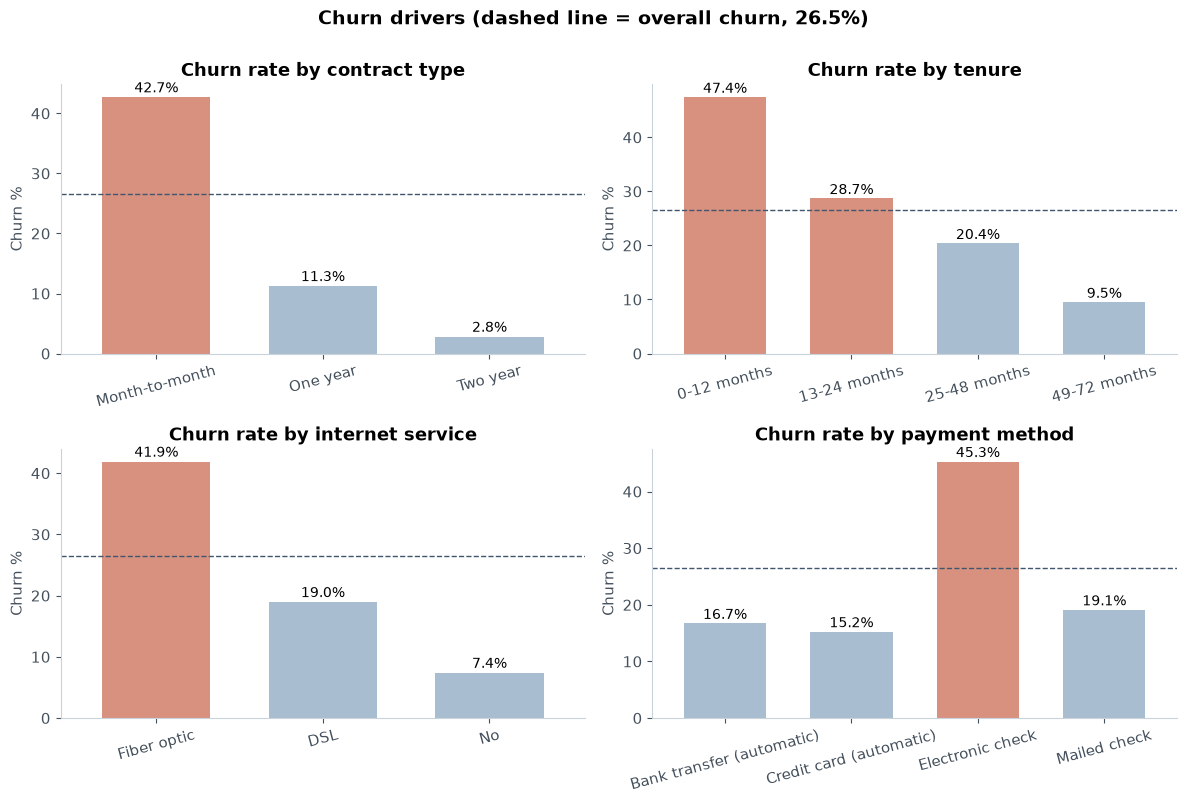

In [6]:
def churn_by(col):
    return (df.groupby(col, observed=True)["ChurnFlag"].mean() * 100).round(2)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
panels = [("Contract", "Contract type", ["Month-to-month", "One year", "Two year"]),
          ("TenureBand", "Tenure", None),
          ("InternetService", "Internet service", ["Fiber optic", "DSL", "No"]),
          ("PaymentMethod", "Payment method", None)]
for ax, (col, title, order) in zip(axes.flat, panels):
    s = churn_by(col)
    if order: s = s.loc[order]
    colors = [CORAL if v >= rate else LIGHT for v in s.values]
    s.plot.bar(ax=ax, color=colors, width=0.65)
    ax.axhline(rate, color=NAVY, ls="--", lw=1)
    ax.set_title(f"Churn rate by {title.lower()}"); ax.set_xlabel(""); ax.set_ylabel("Churn %")
    ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(s.values): ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=10)
fig.suptitle(f"Churn drivers (dashed line = overall churn, {rate:.1f}%)", y=1.0, fontsize=14, fontweight="semibold")
plt.tight_layout(); plt.savefig(IMG / "churn_drivers.png", dpi=150, bbox_inches="tight"); plt.show()

- **Contract:** month-to-month customers churn at 42.7%. Two-year customers churn at only 2.8%.
- **Tenure:** almost half of new customers (47.4%) leave in their first year, and the rate keeps falling the longer they stay.
- **Internet:** fibre customers churn at 41.9%, more than double DSL (19.0%).
- **Payment:** electronic-check payers churn at 45.3%. Customers on automatic payment are at 15-17%.

## 4. Contract and tenure together

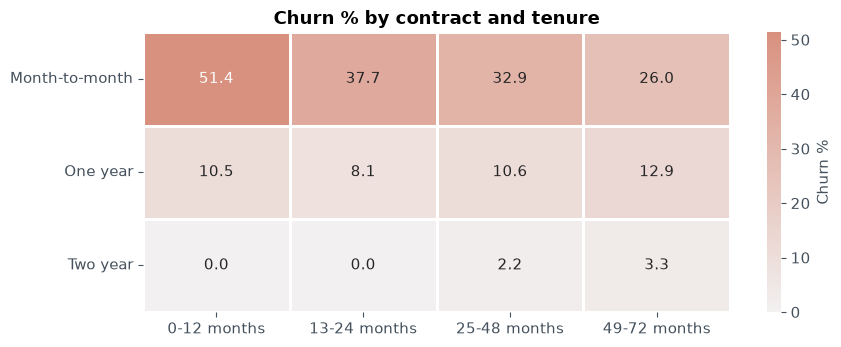

In [7]:
pivot = (df.pivot_table(index="Contract", columns="TenureBand", values="ChurnFlag", aggfunc="mean", observed=True) * 100)
pivot = pivot.loc[["Month-to-month", "One year", "Two year"]]
plt.figure(figsize=(9, 3.6))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap=sns.light_palette(CORAL, as_cmap=True), cbar_kws={"label": "Churn %"},
            linewidths=2, linecolor="white")
plt.title("Churn % by contract and tenure"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.savefig(IMG / "contract_tenure_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

A new month-to-month customer (0-12 months) has a **51.4%** chance of leaving, while the few two-year customers with the same tenure did not leave at all. A longer contract protects against churn at every tenure.

## 5. Is fibre just a contract effect?

Fibre customers might churn more only because more of them are on month-to-month plans. I checked by comparing fibre and DSL **inside each contract type**.

In [8]:
(df[df.InternetService != "No"].pivot_table(index="InternetService", columns="Contract", values="ChurnFlag", aggfunc="mean") * 100).round(1)[["Month-to-month", "One year", "Two year"]]

Contract,Month-to-month,One year,Two year
InternetService,,,
DSL,32.2,9.3,1.9
Fiber optic,54.6,19.3,7.2


Fibre churns more than DSL in **every** contract type (for example 54.6% vs 32.2% on month-to-month), so contract mix does not explain it. Something about the fibre service itself, such as price or quality, is worth looking into.

## 6. Do add-on services help?

In [9]:
net = df[df["InternetService"] != "No"]
rows = []
for svc in ["OnlineSecurity", "TechSupport", "OnlineBackup", "DeviceProtection"]:
    for val in ["Yes", "No"]:
        rows.append({"service": svc, "has_service": val, "churn_%": round(net.loc[net[svc] == val, "ChurnFlag"].mean() * 100, 1)})
addons = pd.DataFrame(rows).pivot(index="service", columns="has_service", values="churn_%")
addons["gap"] = addons["No"] - addons["Yes"]
addons.sort_values("gap", ascending=False)

has_service,No,Yes,gap
service,,,
OnlineSecurity,41.8,14.6,27.2
TechSupport,41.6,15.2,26.4
OnlineBackup,39.9,21.5,18.4
DeviceProtection,39.1,22.5,16.6


Customers with **online security or tech support churn at about 15%, against about 42% without**. These are the strongest protective services, and a good bundle candidate for at-risk fibre customers.

## 7. Which differences are real, and how big are they?

In [10]:
rows = []
for col in ["Contract", "TenureBand", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport",
            "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents", "gender", "PhoneService"]:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(df[col], df["ChurnFlag"]))
    n = len(df); k = min(pd.crosstab(df[col], df["ChurnFlag"]).shape) - 1
    rows.append({"factor": col, "p_value": p, "effect_size (Cramer's V)": round(np.sqrt(chi2 / (n * k)), 3),
                 "linked_to_churn": "Yes" if p < 0.05 else "No"})
pd.DataFrame(rows).sort_values("effect_size (Cramer's V)", ascending=False).reset_index(drop=True)

,factor,p_value,effect_size (Cramer's V),linked_to_churn
0,Contract,5.863038e-258,0.410,Yes
1,TenureBand,2.943770e-185,0.349,Yes
2,OnlineSecurity,2.661150e-185,0.347,Yes
3,TechSupport,1.443084e-180,0.343,Yes
4,InternetService,9.571788e-160,0.322,Yes
5,PaymentMethod,3.682355e-140,0.303,Yes
6,PaperlessBilling,4.073355e-58,0.191,Yes
7,Dependents,4.924922e-43,0.164,Yes
8,SeniorCitizen,1.510067e-36,0.150,Yes
9,Partner,2.139911e-36,0.150,Yes


With 7,000 customers almost any difference looks statistically significant, so I also looked at **effect size** (Cramer's V: 0.1 is small, 0.3 is medium, 0.5 is large). Contract is the strongest factor (0.41), followed by online security, tech support, internet service and payment method (about 0.30 to 0.35). **Gender and phone service are not linked to churn** (p > 0.3, effect size about 0.01), so I left them out of the recommendations.

## 8. The highest-risk segment

In [11]:
seg = df[(df.Contract == "Month-to-month") & (df.InternetService == "Fiber optic")
         & (df.PaymentMethod == "Electronic check") & (df.tenure <= 12)]
print(f"Customers in segment: {len(seg)}")
print(f"Churn rate: {seg.ChurnFlag.mean() * 100:.1f}%")
print(f"Monthly revenue: ${seg.MonthlyCharges.sum():,.0f}")
print(f"Share of all customers: {len(seg) / len(df) * 100:.1f}%  |  share of all churners: {seg.ChurnFlag.sum() / churned * 100:.1f}%")

Customers in segment: 631
Churn rate: 71.2%
Monthly revenue: $51,935
Share of all customers: 9.0%  |  share of all churners: 24.0%


**New month-to-month fibre customers paying by electronic check** are the riskiest group: 631 customers, **71.2% churn**. They are 9% of customers but 24% of all churners.

## 9. Predicting who will leave

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

features = [c for c in df.columns if c not in {"customerID", "Churn", "ChurnFlag", "TenureBand", "ChargeBand"}]
numeric = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical = [c for c in features if c not in numeric]

model = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), numeric),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])),
    ("clf", LogisticRegression(max_iter=2500, class_weight="balanced", random_state=42)),
])
X_train, X_test, y_train, y_test = train_test_split(df[features], df["ChurnFlag"], test_size=0.25,
                                                    random_state=42, stratify=df["ChurnFlag"])
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"Tested on {len(y_test):,} customers the model never saw")
print(f"Accuracy  {accuracy_score(y_test, pred):.1%}")
print(f"Precision {precision_score(y_test, pred):.1%}")
print(f"Recall    {recall_score(y_test, pred):.1%}")
print(f"AUC       {roc_auc_score(y_test, proba):.3f}")
pd.DataFrame(confusion_matrix(y_test, pred), index=["Actually stayed", "Actually left"], columns=["Predicted stay", "Predicted leave"])

Tested on 1,761 customers the model never saw
Accuracy  75.0%
Precision 51.9%
Recall    79.7%
AUC       0.846


,Predicted stay,Predicted leave
Actually stayed,949,345
Actually left,95,372


**Why recall?** Missing a customer who is about to leave costs more than one extra courtesy call. So I used balanced class weights and judged the model mainly on recall. It catches about **4 in 5 leavers**. Precision is lower (about half of the customers it flags really leave), which is an acceptable price for a call list.

## 10. Is a more complex model better?

A single train/test split can be lucky, so I used 5-fold cross-validation and compared Logistic Regression with two stronger models and a do-nothing baseline.

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

def make(clf):
    return Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), numeric),
                                                 ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])), ("clf", clf)])
candidates = {
    "Baseline (everyone stays)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2500, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, clf in candidates.items():
    scores = cross_val_score(make(clf), df[features], df["ChurnFlag"], cv=cv, scoring="roc_auc")
    rows.append({"model": name, "AUC (5-fold average)": round(scores.mean(), 3), "spread": round(scores.std(), 3)})
pd.DataFrame(rows)

,model,AUC (5-fold average),spread
0,Baseline (everyone stays),0.500,0.000
1,Logistic Regression,0.845,0.013
2,Random Forest,0.844,0.012
3,Gradient Boosting,0.847,0.011


All three real models land at an AUC of about **0.845**, so the extra complexity buys nothing here. I kept **Logistic Regression**: it is just as accurate and I can explain every factor to a business team.

**Choosing the cut-off.** The model gives each customer a probability. Where I draw the line decides how many customers get a call and how many leavers I catch.

In [14]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    flagged = (proba >= t)
    rows.append({"call customers above": t, "share of customers called": f"{flagged.mean():.0%}",
                 "leavers caught (recall)": f"{recall_score(y_test, flagged):.0%}",
                 "calls that were real leavers (precision)": f"{precision_score(y_test, flagged):.0%}"})
pd.DataFrame(rows)

,call customers above,share of customers called,leavers caught (recall),calls that were real leavers (precision)
0,0.3,57%,93%,43%
1,0.4,49%,87%,47%
2,0.5,41%,80%,52%
3,0.6,34%,72%,55%


A low cut-off (0.3) catches 93% of leavers but means calling more than half of all customers. A higher one (0.6) is cheaper but misses more. A real team would choose based on what a call costs and what a saved customer is worth. I used 0.30 and 0.60 to split customers into Low, Medium and High risk.

## 11. Risk bands and who to call first

        customers  churn_rate
band                         
Low           761        4.47
Medium        393       24.94
High          607       55.19

Contacting the riskiest 30% of customers reaches 66.4% of everyone who left


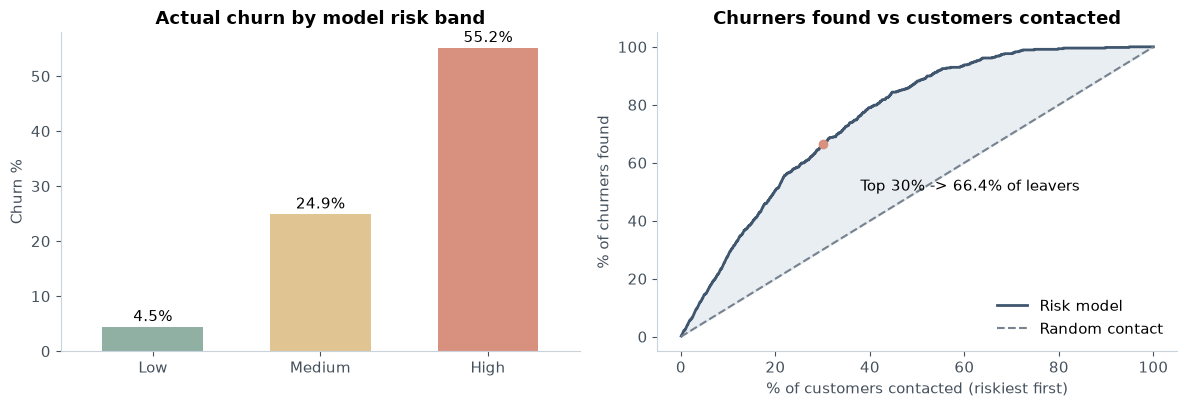

In [15]:
test = pd.DataFrame({"score": proba, "actual": y_test.values})
test["band"] = pd.cut(test["score"], [-0.01, 0.2999, 0.5999, 1.0], labels=["Low", "Medium", "High"])
bands = test.groupby("band", observed=True)["actual"].agg(customers="count", churn_rate=lambda s: round(s.mean() * 100, 2))
print(bands)

ranked = test.sort_values("score", ascending=False).reset_index(drop=True)
gains = ranked["actual"].cumsum() / ranked["actual"].sum() * 100
top30 = gains.iloc[int(len(ranked) * 0.30) - 1]
print(f"\nContacting the riskiest 30% of customers reaches {top30:.1f}% of everyone who left")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
bands["churn_rate"].plot.bar(ax=ax[0], color=[SAGE, SAND, CORAL], width=0.6)
ax[0].set_title("Actual churn by model risk band"); ax[0].set_xlabel(""); ax[0].set_ylabel("Churn %"); ax[0].tick_params(axis="x", rotation=0)
for i, v in enumerate(bands["churn_rate"]): ax[0].text(i, v + 1, f"{v:.1f}%", ha="center")
x = np.arange(1, len(gains) + 1) / len(gains) * 100
ax[1].plot(x, gains, color=NAVY, lw=2, label="Risk model")
ax[1].plot([0, 100], [0, 100], color="#76828E", ls="--", label="Random contact")
ax[1].fill_between(x, gains, x, color=BLUE, alpha=0.15)
ax[1].scatter([30], [top30], color=CORAL, zorder=5); ax[1].annotate(f"Top 30% -> {top30:.1f}% of leavers", (30, top30), (38, top30 - 16))
ax[1].set_title("Churners found vs customers contacted"); ax[1].set_xlabel("% of customers contacted (riskiest first)"); ax[1].set_ylabel("% of churners found"); ax[1].legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig(IMG / "model_results.png", dpi=150, bbox_inches="tight"); plt.show()

The bands separate customers well: **4.5% of Low-risk customers actually left, 24.9% of Medium and 55.2% of High**. The riskiest 30% of customers hold **66.4% of all leavers**, so a team that calls less than a third of customers still reaches two-thirds of the people about to go.

## 12. What is it worth? (rough estimate)

In [16]:
rows = [{"save_rate": f"{r:.0%}", "annual_revenue_kept": f"${lost * 12 * r:,.0f}"} for r in [0.05, 0.10, 0.15, 0.20]]
pd.DataFrame(rows)

,save_rate,annual_revenue_kept
0,5%,"$83,479"
1,10%,"$166,957"
2,15%,"$250,436"
3,20%,"$333,914"


The customers who left paid **$139,131 a month**. If a campaign kept just **10%** of them, that would protect about **$166,957 a year** ($139,131 x 12 x 10%).

This is a rough estimate. It uses revenue, not profit, it ignores what the campaign costs, and it assumes the saved customers would stay a full year.

## Recommendations

1. **Look after new customers early.** Check in at 30, 90 and 180 days. Almost half of new customers leave in the first year.
2. **Offer longer contracts** to month-to-month customers, starting with the High-risk band.
3. **Move electronic-check payers to automatic payment.**
4. **Bundle online security and tech support**, especially for fibre customers.
5. **Look into fibre pricing and quality.** Fibre churns more than DSL at every tenure and on every contract type.
6. **Score customers monthly** and assign actions by risk band.

## Limitations

- This is public data for a hypothetical company, so a real telecom business may look different.
- It is one snapshot. I have no complaints, usage or satisfaction data, which would likely improve the model.
- The results show what goes together with churn, not what causes it. Any action should be tested on a small group first.
- I compared three models but did not tune them heavily. Tuning is unlikely to change the picture much, given how close they were.
- The revenue estimate is gross revenue and ignores campaign cost.